In [3]:
import pandas as pd

activity =pd.read_csv('dailyActivity_merged.csv')
sleep = pd.read_csv('sleepDay_merged.csv')
print(activity.head())
print(sleep.head())
rows_activity = len(activity)
print("Rows in daily activity dataset:", rows_activity)
rows_sleep = len(sleep)
print("Rows in daily activity dataset:", rows_sleep)

           Id ActivityDate  TotalSteps  TotalDistance  TrackerDistance  \
0  1503960366    4/12/2016       13162           8.50             8.50   
1  1503960366    4/13/2016       10735           6.97             6.97   
2  1503960366    4/14/2016       10460           6.74             6.74   
3  1503960366    4/15/2016        9762           6.28             6.28   
4  1503960366    4/16/2016       12669           8.16             8.16   

   LoggedActivitiesDistance  VeryActiveDistance  ModeratelyActiveDistance  \
0                       0.0                1.88                      0.55   
1                       0.0                1.57                      0.69   
2                       0.0                2.44                      0.40   
3                       0.0                2.14                      1.26   
4                       0.0                2.71                      0.41   

   LightActiveDistance  SedentaryActiveDistance  VeryActiveMinutes  \
0                 6.06

In [ ]:
activity['ActivityDate'] = pd.to_datetime(activity['ActivityDate'])
sleep['SleepDay'] =pd.to_datetime(sleep['SleepDay'])

activity['Total_Active_Minutes'] = (activity['VeryActiveMinutes'] + activity['FairlyActiveMinutes'] + activity['LightlyActiveMinutes'])


print(activity[['Id','ActivityDate','Total_Active_Minutes']].head())

           Id ActivityDate  Total_Active_Minutes
0  1503960366   2016-04-12                   366
1  1503960366   2016-04-13                   257
2  1503960366   2016-04-14                   222
3  1503960366   2016-04-15                   272
4  1503960366   2016-04-16                   267


In [5]:
merge= pd.merge(activity, sleep, left_on=['Id','ActivityDate'], right_on=['Id','SleepDay'], how='inner')
print(merge.head())
rows_merge = len(merge)
print("Rows in daily activity dataset:", rows_merge)

           Id ActivityDate  TotalSteps  TotalDistance  TrackerDistance  \
0  1503960366   2016-04-12       13162           8.50             8.50   
1  1503960366   2016-04-13       10735           6.97             6.97   
2  1503960366   2016-04-15        9762           6.28             6.28   
3  1503960366   2016-04-16       12669           8.16             8.16   
4  1503960366   2016-04-17        9705           6.48             6.48   

   LoggedActivitiesDistance  VeryActiveDistance  ModeratelyActiveDistance  \
0                       0.0                1.88                      0.55   
1                       0.0                1.57                      0.69   
2                       0.0                2.14                      1.26   
3                       0.0                2.71                      0.41   
4                       0.0                3.19                      0.78   

   LightActiveDistance  SedentaryActiveDistance  VeryActiveMinutes  \
0                 6.06

In [6]:
drop_columns = ['TotalDistance', 'TrackerDistance', 'LoggedActivitiesDistance', 'VeryActiveDistance', 'ModeratelyActiveDistance', 'LightActiveDistance', 'SedentaryActiveDistance','VeryActiveMinutes', 'FairlyActiveMinutes', 'LightlyActiveMinutes', 'SedentaryMinutes', 'Calories', 'TotalSleepRecords', 'SleepDay']


drop_merge = merge.drop(columns=drop_columns)
print(drop_merge.head())
print(drop_merge.isna().sum())

           Id ActivityDate  TotalSteps  Total_Active_Minutes  \
0  1503960366   2016-04-12       13162                   366   
1  1503960366   2016-04-13       10735                   257   
2  1503960366   2016-04-15        9762                   272   
3  1503960366   2016-04-16       12669                   267   
4  1503960366   2016-04-17        9705                   222   

   TotalMinutesAsleep  TotalTimeInBed  
0                 327             346  
1                 384             407  
2                 412             442  
3                 340             367  
4                 700             712  
Id                      0
ActivityDate            0
TotalSteps              0
Total_Active_Minutes    0
TotalMinutesAsleep      0
TotalTimeInBed          0
dtype: int64


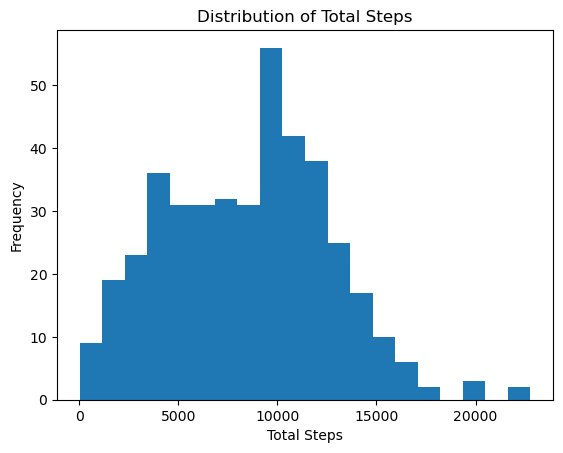

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
plt.hist(merge['TotalSteps'], bins=20)

plt.title("Distribution of Total Steps")
plt.xlabel("Total Steps")
plt.ylabel("Frequency")

plt.show()

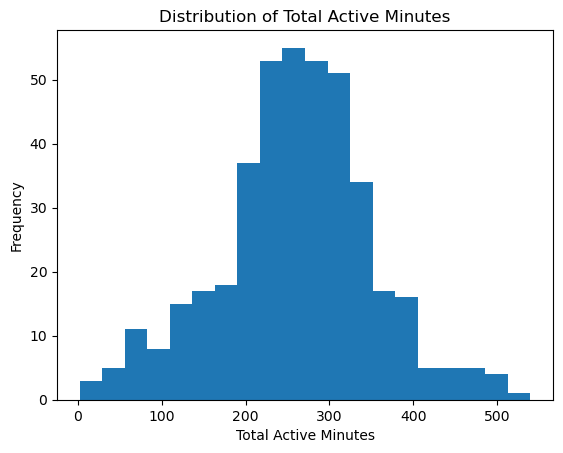

In [8]:
plt.hist(merge['Total_Active_Minutes'], bins=20)

plt.title("Distribution of Total Active Minutes")
plt.xlabel("Total Active Minutes")
plt.ylabel("Frequency")

plt.show()

Correlation of steps and sleep: -0.1868664989254595
Correlation of active minutes and sleep: -0.06376059520667852


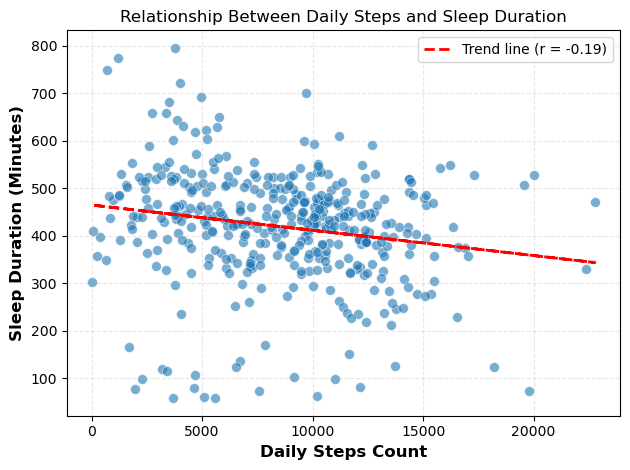

In [12]:
steps_sleep = merge['TotalSteps'].corr(merge['TotalMinutesAsleep'])
active_minutes_sleep = merge['Total_Active_Minutes'].corr(merge['TotalMinutesAsleep'])
print('Correlation of steps and sleep:', steps_sleep)
print('Correlation of active minutes and sleep:', active_minutes_sleep)

import numpy as np
scatter = plt.scatter(merge['TotalSteps'], 
                      merge['TotalMinutesAsleep'], 
                      alpha=0.6, 
                      edgecolors='w', 
                      linewidth=0.5,
                      s=50)

# Add trend line (linear regression)
z = np.polyfit(merge['TotalSteps'], merge['TotalMinutesAsleep'], 1)
p = np.poly1d(z)
plt.plot(merge['TotalSteps'], p(merge['TotalSteps']), 
         color='red', 
         linewidth=2, 
         linestyle='--',
         label=f'Trend line (r = {steps_sleep:.2f})')

# Labels and title
plt.xlabel('Daily Steps Count', fontsize=12, fontweight='bold')
plt.ylabel('Sleep Duration (Minutes)', fontsize=12, fontweight='bold')
plt.title('Relationship Between Daily Steps and Sleep Duration')

# Add grid for better readability
plt.grid(True, alpha=0.3, linestyle='--')

# Add legend
plt.legend()



# Adjust layout to prevent label cutoff
plt.tight_layout()

# Show the plot
plt.show()

   ID  Age  Gender              Bedtime          Wakeup time  Sleep duration  \
0   1   65  Female  2021-03-06 01:00:00  2021-03-06 07:00:00             6.0   
1   2   69    Male  2021-12-05 02:00:00  2021-12-05 09:00:00             7.0   
2   3   40  Female  2021-05-25 21:30:00  2021-05-25 05:30:00             8.0   
3   4   40  Female  2021-11-03 02:30:00  2021-11-03 08:30:00             6.0   
4   5   57    Male  2021-03-13 01:00:00  2021-03-13 09:00:00             8.0   

   Sleep efficiency  REM sleep percentage  Deep sleep percentage  \
0              0.88                    18                     70   
1              0.66                    19                     28   
2              0.89                    20                     70   
3              0.51                    23                     25   
4              0.76                    27                     55   

   Light sleep percentage  Awakenings  Caffeine consumption  \
0                      12         0.0          

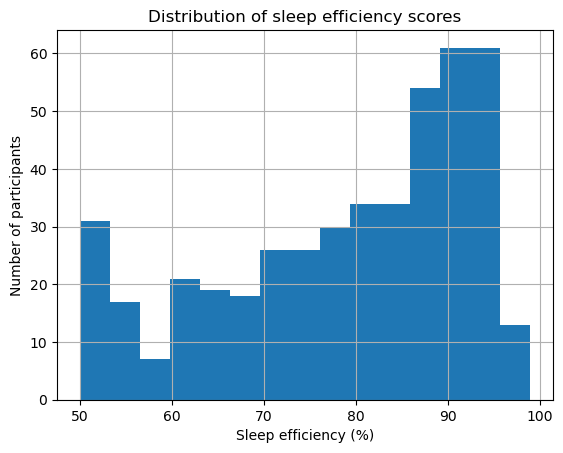

Average sleep efficiency: 78.89159292035399


In [ ]:
import matplotlib.pyplot as plt
sleep_efficiency = pd.read_csv('sleep_efficiency.csv')
print(sleep_efficiency.head())

sleep_efficiency['Sleep efficiency'] = sleep_efficiency['Sleep efficiency']*100
sleep_efficiency['Sleep efficiency'].hist(bins=15)
plt.title('Distribution of sleep efficiency scores')
plt.xlabel('Sleep efficiency (%)')
plt.ylabel('Number of participants')
plt.show()
average_sleep_efficiency = sleep_efficiency['Sleep efficiency'].mean()
print('Average sleep efficiency:', average_sleep_efficiency)

Gender
Female    78.754464
Male      79.026316
Name: Sleep efficiency, dtype: float64


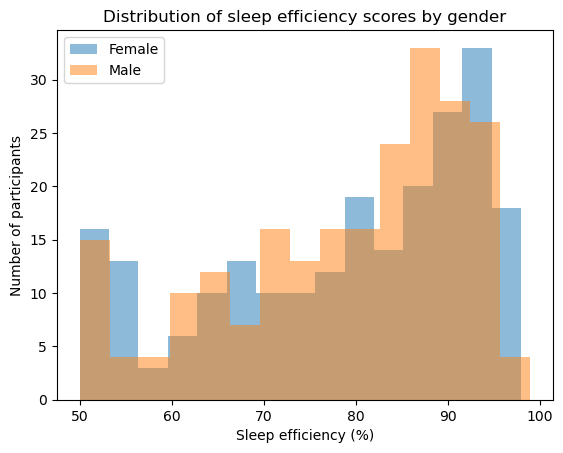

In [ ]:
gender_avg_sleep_efficiency = sleep_efficiency.groupby('Gender')['Sleep efficiency'].mean()
print (gender_avg_sleep_efficiency)
for gender in sleep_efficiency['Gender'].unique():
    gender_data = sleep_efficiency[sleep_efficiency['Gender'] == gender]
    plt.hist(gender_data['Sleep efficiency'], bins=15, alpha=0.5, label=gender)
plt.title('Distribution of sleep efficiency scores by gender')
plt.xlabel('Sleep efficiency (%)')
plt.ylabel('Number of participants')
plt.legend()
plt.show()

0      327
1      384
2      412
3      340
4      700
      ... 
408    343
409    503
410    415
411    516
412    439
Name: TotalMinutesAsleep, Length: 413, dtype: int64 0      346
1      407
2      442
3      367
4      712
      ... 
408    360
409    527
410    423
411    545
412    463
Name: TotalTimeInBed, Length: 413, dtype: int64
0    94.508671
1    94.348894
2    93.212670
3    92.643052
4    98.314607
dtype: float64


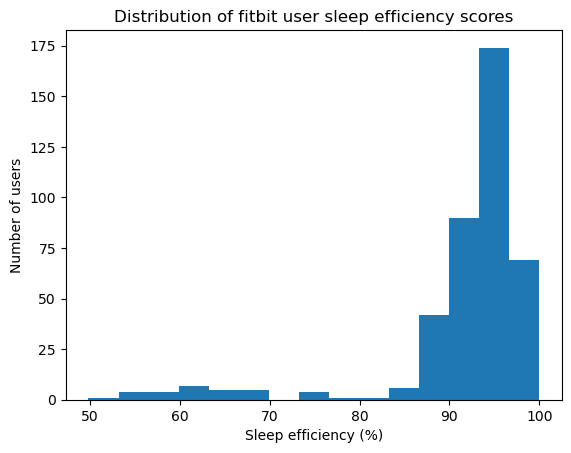

Average sleep efficiency: 91.67692065151059


In [ ]:
sleep1_efficiency = (merge['TotalMinutesAsleep'] / merge['TotalTimeInBed']*100)
print(merge['TotalMinutesAsleep'],  merge['TotalTimeInBed'])
print(sleep1_efficiency.head())
plt.hist(sleep1_efficiency, bins=15)
plt.title('Distribution of fitbit user sleep efficiency scores')
plt.xlabel('Sleep efficiency (%)')
plt.ylabel('Number of users')
plt.show()
average_sleep1_efficiency = sleep1_efficiency.mean()
print('Average sleep efficiency:', average_sleep1_efficiency)

Average sleep duration: 447.9424778761062


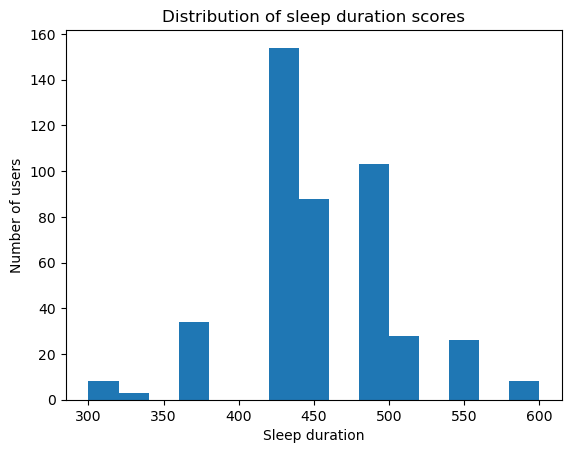

In [ ]:
sleep_efficiency['Bedtime'] = pd.to_datetime(sleep_efficiency['Bedtime'])
sleep_efficiency['Wakeup time'] = pd.to_datetime(sleep_efficiency['Wakeup time'])
sleep_efficiency['Sleep Duration'] = (sleep_efficiency['Wakeup time'] - sleep_efficiency['Bedtime']).dt.total_seconds() / 3600
sleep_efficiency.loc[sleep_efficiency['Sleep Duration'] < 0, 'Sleep Duration'] += 24
average_sleep_duration = sleep_efficiency['Sleep Duration'].mean()
average_sleep_duration_minutes = average_sleep_duration * 60
print('Average sleep duration:', average_sleep_duration_minutes)

plt.hist(sleep_efficiency['Sleep Duration']* 60, bins=15)
plt.title('Distribution of sleep duration scores')
plt.xlabel('Sleep duration')
plt.ylabel('Number of users')
plt.show()

In [ ]:
drop_merge.to_csv("drop_merged_fitbit.csv", index=False)

PermissionError: [Errno 13] Permission denied: 'drop_merged_fitbit.csv'

In [ ]:
import pandas as pd
import plotly.express as px
from dash import Dash, dcc, html, Input, Output
import dash_bootstrap_components as dbc

# Load data
df = pd.read_csv("drop_merged_fitbit.csv")
df["ActivityDate"] = pd.to_datetime(df["ActivityDate"])
df = df.sort_values("ActivityDate")

# Moving averages
df["Steps_MA7"] = df["TotalSteps"].rolling(7).mean()
df["ActiveMin_MA7"] = df["Total_Active_Minutes"].rolling(7).mean()
df["Sleep_MA7"] = df["TotalMinutesAsleep"].rolling(7).mean()

def kpi_card(title, value):
    return dbc.Card(
        dbc.CardBody([
            html.H6(title, style={"margin-bottom": "4px"}),
            html.H4(str(value))
        ]),
        style={"textAlign": "center", "padding": "8px", "height": "110px"}
    )


app = Dash(__name__, external_stylesheets=[dbc.themes.BOOTSTRAP])

app.layout = html.Div([
    html.H2(
        "Fitbit physical activity and sleep duration dashboard",
        style={"textAlign": "center", "margin-bottom": "12px"}
    ),

    html.Div(
        dcc.DatePickerRange(
            id="date_range",
            min_date_allowed=df["ActivityDate"].min(),
            max_date_allowed=df["ActivityDate"].max(),
            start_date=df["ActivityDate"].min(),
            end_date=df["ActivityDate"].max(),
        ),
        style={"textAlign": "center", "margin-bottom": "14px"}
    ),

    dbc.Row([
        dbc.Col(html.Div(id="kpi_steps"), width=4),
        dbc.Col(html.Div(id="kpi_active"), width=4),
        dbc.Col(html.Div(id="kpi_sleep"), width=4),
    ], style={"marginBottom": "12px"}),

    dbc.Row([
        dbc.Col(dcc.Graph(id="steps_graph", config={"displayModeBar": False}), width=4),
        dbc.Col(dcc.Graph(id="active_graph", config={"displayModeBar": False}), width=4),
        dbc.Col(dcc.Graph(id="sleep_graph", config={"displayModeBar": False}), width=4),
    ])
])


@app.callback(
    [
        Output("steps_graph", "figure"),
        Output("active_graph", "figure"),
        Output("sleep_graph", "figure"),
        Output("kpi_steps", "children"),
        Output("kpi_active", "children"),
        Output("kpi_sleep", "children"),
    ],
    [Input("date_range", "start_date"), Input("date_range", "end_date")]
)
def update_dashboard(start_date, end_date):
    dff = df[(df["ActivityDate"] >= start_date) & (df["ActivityDate"] <= end_date)]

    avg_steps = round(dff["TotalSteps"].mean())
    avg_active = round(dff["Total_Active_Minutes"].mean())
    avg_sleep = round(dff["TotalMinutesAsleep"].mean())

    fig_steps = px.line(dff, x="ActivityDate", y="TotalSteps", title="Steps")
    fig_steps.add_scatter(x=dff["ActivityDate"], y=dff["Steps_MA7"], mode="lines", name="7-day MA")
    fig_steps.update_layout(height=300, margin=dict(l=20, r=20, t=40, b=20))

    fig_active = px.line(dff, x="ActivityDate", y="Total_Active_Minutes", title="Active minutes")
    fig_active.add_scatter(x=dff["ActivityDate"], y=dff["ActiveMin_MA7"], mode="lines", name="7-day MA")
    fig_active.update_layout(height=300, margin=dict(l=20, r=20, t=40, b=20))

    fig_sleep = px.line(dff, x="ActivityDate", y="TotalMinutesAsleep", title="Sleep duration")
    fig_sleep.add_scatter(x=dff["ActivityDate"], y=dff["Sleep_MA7"], mode="lines", name="7-day MA")
    fig_sleep.update_layout(height=300, margin=dict(l=20, r=20, t=40, b=20))

    return (
        fig_steps,
        fig_active,
        fig_sleep,
        kpi_card("Avg steps", avg_steps),
        kpi_card("Avg active minutes", avg_active),
        kpi_card("Avg sleep (min)", avg_sleep),
    )


if __name__ == "__main__":
    app.run(debug=True)


In [ ]:
import pandas as pd
import plotly.express as px
from dash import Dash, dcc, html, Input, Output
import dash_bootstrap_components as dbc

# Load and prepare data
df = pd.read_csv("drop_merged_fitbit.csv")
df["ActivityDate"] = pd.to_datetime(df["ActivityDate"])
df = df.sort_values("ActivityDate")

# Calculate moving averages
for col, ma_col in [("TotalSteps", "Steps_MA7"), 
                    ("Total_Active_Minutes", "ActiveMin_MA7"), 
                    ("TotalMinutesAsleep", "Sleep_MA7")]:
    df[ma_col] = df[col].rolling(7).mean()

# Minimal KPI card component
def kpi_card(title, value):
    return dbc.Card(
        dbc.CardBody([html.H6(title), html.H4(str(value))]),
        style={"textAlign": "center", "padding": "10px"}
    )

app = Dash(__name__, external_stylesheets=[dbc.themes.BOOTSTRAP])

app.layout = html.Div([
    html.H4("Fitbit activity and sleep dashboard", 
            style={"textAlign": "center", "marginBottom": "20px"}),
    
    html.Div(
        dcc.DatePickerRange(
            id="date_range",
            min_date_allowed=df["ActivityDate"].min(),
            max_date_allowed=df["ActivityDate"].max(),
            start_date=df["ActivityDate"].min(),
            end_date=df["ActivityDate"].max(),
        ), style={"textAlign": "center", "marginBottom": "20px"}
    ),

    dbc.Row([
        dbc.Col(html.Div(id="kpi_steps"), width=4),
        dbc.Col(html.Div(id="kpi_active"), width=4),
        dbc.Col(html.Div(id="kpi_sleep"), width=4),
    ], style={"marginBottom": "20px"}),

    dbc.Row([
        dbc.Col(dcc.Graph(id="steps_graph", config={"displayModeBar": False}), width=4),
        dbc.Col(dcc.Graph(id="active_graph", config={"displayModeBar": False}), width=4),
        dbc.Col(dcc.Graph(id="sleep_graph", config={"displayModeBar": False}), width=4),
    ])
])

@app.callback(
    [Output("steps_graph", "figure"),
     Output("active_graph", "figure"), 
     Output("sleep_graph", "figure"),
     Output("kpi_steps", "children"),
     Output("kpi_active", "children"),
     Output("kpi_sleep", "children")],
    [Input("date_range", "start_date"), 
     Input("date_range", "end_date")]
)
def update_dashboard(start_date, end_date):
    dff = df[(df["ActivityDate"] >= start_date) & (df["ActivityDate"] <= end_date)]
    
    # Calculate averages
    avg_steps = round(dff["TotalSteps"].mean())
    avg_active = round(dff["Total_Active_Minutes"].mean())
    avg_sleep = round(dff["TotalMinutesAsleep"].mean())
    
    # Create figures with consistent styling
    figures = []
    for y_col, ma_col, title in [("TotalSteps", "Steps_MA7", "Daily Steps"),
                                 ("Total_Active_Minutes", "ActiveMin_MA7", "Active Minutes"),
                                 ("TotalMinutesAsleep", "Sleep_MA7", "Sleep Duration")]:
        fig = px.line(dff, x="ActivityDate", y=y_col, title=title)
        fig.add_scatter(x=dff["ActivityDate"], y=dff[ma_col], mode="lines", name="7-Day MA", line=dict(dash="dot"))
        fig.update_layout(height=280, margin=dict(l=30, r=30, t=40, b=30), showlegend=False)
        figures.append(fig)
    
    return (*figures, 
            kpi_card("Avg Steps", avg_steps),
            kpi_card("Avg Active Minutes", avg_active), 
            kpi_card("Avg sleep", "{}h {}m".format(avg_sleep // 60, avg_sleep % 60)))

if __name__ == "__main__":
    app.run(debug=True)